# UV parameterization

`parameterize(mesh)` gives a triangle surface a UV atlas: it cuts the surface into charts, flattens each without flipping a triangle (least-squares conformal maps, else mean-value coordinates), halves a chart that stretches too much, and shelf-packs the charts into the unit square. The result carries `point_data["uv"]`, split at its seams, and the OBJ (`vt`), glTF (`TEXCOORD_0`) and USD (`primvars:st`) writers turn it into texture coordinates. See `doc/parameterize.md`.

In [1]:
import os
import subprocess
import sys
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def checker(uv, n=16):
    """A black-and-white checker image looked up at texture coordinates."""
    return ((np.floor(uv[..., 0] * n) + np.floor(uv[..., 1] * n)) % 2).astype(float)


def draw_textured(ax, mesh, title, view=(10, -60)):
    """The surface with a checker texture through its uv: PyVista's textured
    render embedded as an image when GL is available, else matplotlib faces
    coloured by the checker at their centroid's uv, shaded by their normal."""
    tris = mesh.cells_dict['triangle']
    uv = mesh.point_data['uv']
    if pv is not None:
        faces = np.hstack([np.full((len(tris), 1), 3), tris]).ravel()
        grid = pv.PolyData(mesh.points, faces)
        grid.active_texture_coordinates = uv.astype(np.float32)
        img = (np.kron(checker(np.stack(np.meshgrid(np.arange(16) / 16, np.arange(16) / 16), -1) + 1e-3),
                       np.ones((32, 32))) * 255).astype(np.uint8)
        tex = pv.Texture(np.dstack([img, img, img]))
        pl = pv.Plotter(off_screen=True, window_size=(700, 600))
        pl.add_mesh(grid, texture=tex, smooth_shading=True)
        pl.camera_position = 'xz'
        pl.camera.azimuth = -30
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
        ax.axis('off')
    else:
        p = mesh.points[tris]
        n = np.cross(p[:, 1] - p[:, 0], p[:, 2] - p[:, 0])
        n /= np.linalg.norm(n, axis=1)[:, None] + 1e-300
        light = np.array([0.4, -0.6, 0.7]) / np.linalg.norm([0.4, -0.6, 0.7])
        shade = 0.35 + 0.65 * np.clip(n @ light, 0, 1)
        c = 0.25 + 0.7 * checker(uv[tris].mean(axis=1))
        rgb = np.clip((c * shade)[:, None] * np.array([1.0, 0.85, 0.6]), 0, 1)
        ax.add_collection3d(Poly3DCollection(p, facecolors=rgb, edgecolor='none'))
        lo, hi = mesh.points.min(0), mesh.points.max(0)
        mid, r = (lo + hi) / 2, (hi - lo).max() / 2
        ax.set_xlim(mid[0] - r, mid[0] + r); ax.set_ylim(mid[1] - r, mid[1] + r); ax.set_zlim(mid[2] - r, mid[2] + r)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(*view)
        ax.set_axis_off()
    ax.set_title(title)


def draw_atlas(ax, mesh, title):
    """The charts in the unit square, each in its own colour."""
    tris = mesh.cells_dict['triangle']
    uv = mesh.point_data['uv']
    chart = mesh.cell_data_dict['parameterize:chart']['triangle']
    cmap = plt.get_cmap('tab20')
    ax.add_collection(PolyCollection(uv[tris], facecolors=cmap(chart % 20), edgecolors='none'))
    ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], 'k-', lw=0.8)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect('equal')
    ax.set_xlabel('u'); ax.set_ylabel('v'); ax.set_title(title)

No GL available: rendering with matplotlib.


## The bunny's atlas

The Stanford bunny (112k triangles, one closed piece with holes underneath) is cut into charts that each flatten with no flipped triangle and an L2 stretch under 2; the atlas packs them, and a checker texture looked up through `uv` lands on the surface with nearly square cells everywhere -- the sign of a map that keeps angles and, after the stretch test, lengths.

{'num_charts': 47, 'num_flipped': 0, 'stretch': 1.1087523433043955, 'packing_efficiency': 0.3505461553420238, 'num_seam_points': 2936}
56203 points in, 59139 out (seams split)


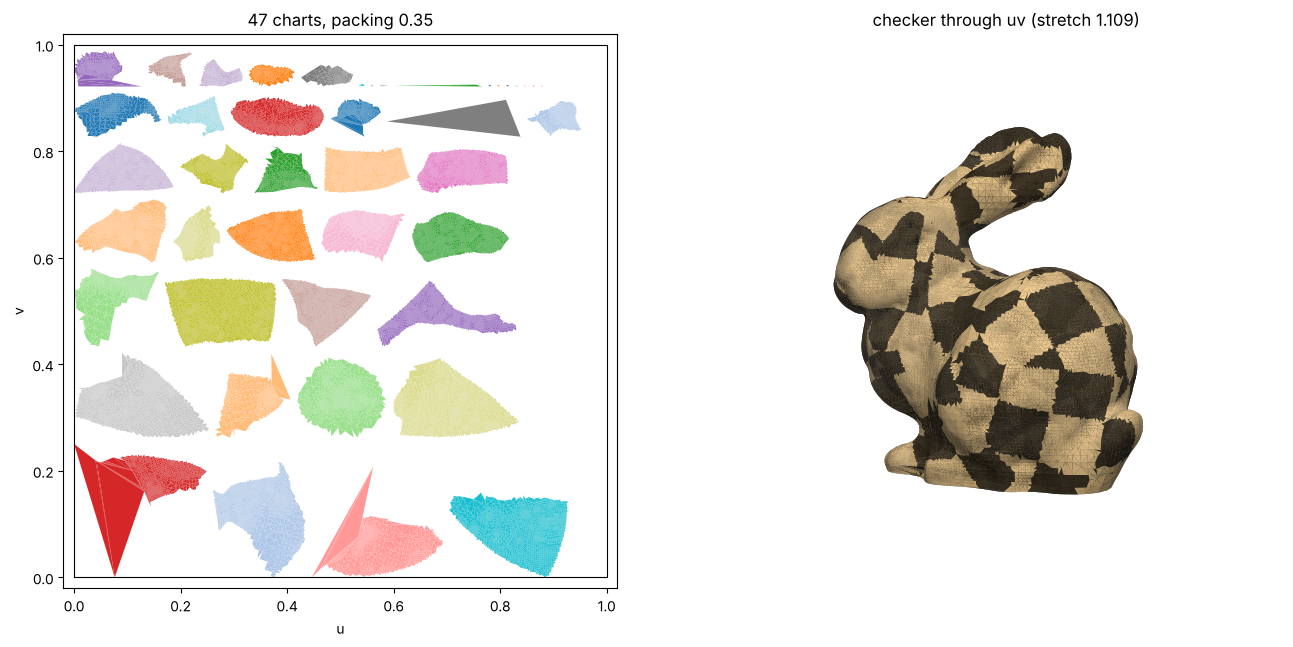

In [2]:
bunny = mp.read(os.path.join('..', 'data', 'Bunny.stl'))
out, report = mp.parameterize(bunny, return_report=True)
print(report)
print(f"{len(bunny.points)} points in, {len(out.points)} out (seams split)")

fig = plt.figure(figsize=(14, 6.5))
ax = fig.add_subplot(1, 2, 1)
draw_atlas(ax, out, f"{report['num_charts']} charts, packing {report['packing_efficiency']:.2f}")
ax = fig.add_subplot(1, 2, 2, projection=None if pv else '3d')
draw_textured(ax, out, f"checker through uv (stretch {report['stretch']:.3f})")
plt.tight_layout()
plt.show()

## The probe: a disc is one chart with nothing flipped

A flat disc is a single chart, its map an isometry (stretch 1), and no triangle flips. Lowering `max_stretch` on a curved surface trades more charts for less distortion: the icosphere's two hemispheres stretch by 8%, four charts by 1%, nine by a quarter of that.

{'num_charts': 1, 'num_flipped': 0, 'stretch': 1.0000000000000029}
max_stretch 2.0: 2 charts, stretch 1.080, packing 0.37


max_stretch 1.06: 4 charts, stretch 1.011, packing 0.33


max_stretch 1.01: 9 charts, stretch 1.002, packing 0.49


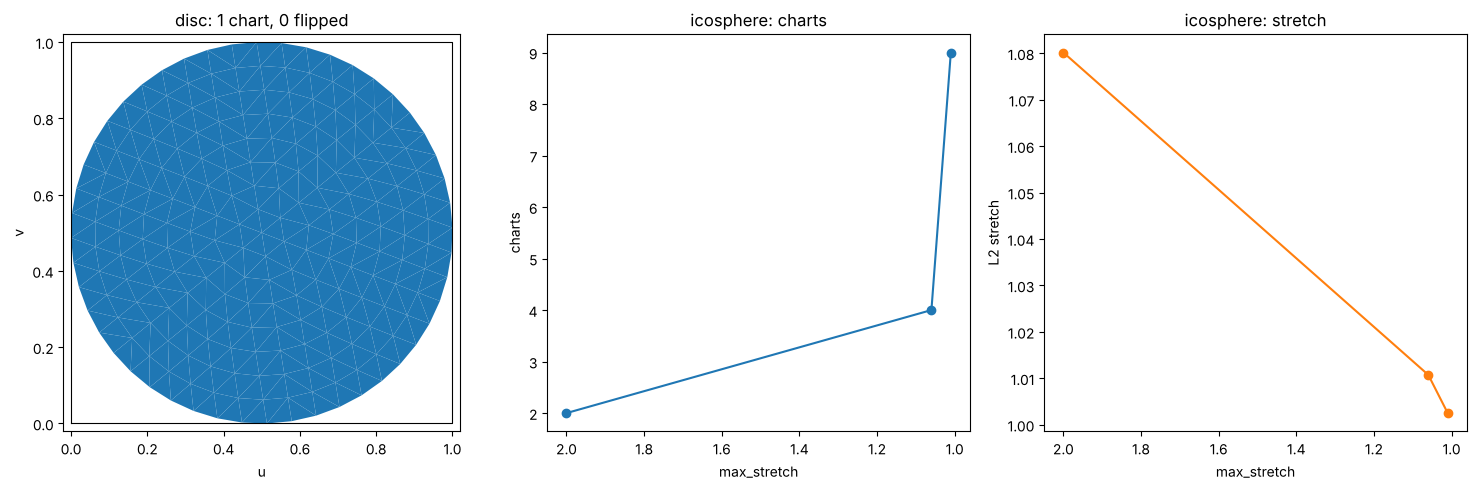

In [3]:
disc = mp.disk(1.0, 8, cell_type='triangle')
d_out, d_rep = mp.parameterize(disc, return_report=True)
print({k: d_rep[k] for k in ('num_charts', 'num_flipped', 'stretch')})

sphere = mp.icosa_sphere(subdivisions=4)
rows = []
for limit in (2.0, 1.06, 1.01):
    _, rep = mp.parameterize(sphere, max_stretch=limit, return_report=True)
    rows.append((limit, rep['num_charts'], rep['stretch'], rep['packing_efficiency']))
    print(f"max_stretch {limit}: {rep['num_charts']} charts, stretch {rep['stretch']:.3f}, packing {rep['packing_efficiency']:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
draw_atlas(axes[0], d_out, f"disc: {d_rep['num_charts']} chart, {d_rep['num_flipped']} flipped")
limits, charts, stretch, _ = zip(*rows)
axes[1].plot(limits, charts, 'o-')
axes[1].set_xlabel('max_stretch'); axes[1].set_ylabel('charts'); axes[1].invert_xaxis()
axes[1].set_title('icosphere: charts')
axes[2].plot(limits, stretch, 'o-', color='C1')
axes[2].set_xlabel('max_stretch'); axes[2].set_ylabel('L2 stretch'); axes[2].invert_xaxis()
axes[2].set_title('icosphere: stretch')
plt.tight_layout()
plt.show()

## Into the files

OBJ writes one `vt` per point and every face corner as `v/vt`; glTF writes `TEXCOORD_0` (with `v` flipped, glTF's origin being the image's top left) and both engines write the same bytes; USD writes `primvars:st`. Each reads back as `uv`.

In [4]:
with tempfile.TemporaryDirectory() as tmp:
    for ext in ('obj', 'glb', 'usda'):
        path = os.path.join(tmp, f'bunny.{ext}')
        try:
            mp.write(path, out)
        except Exception as exc:  # USD needs usd-core
            print(f'{ext}: skipped ({type(exc).__name__})')
            continue
        back = mp.read(path)
        uv = back.point_data.get('uv')
        print(f"{ext:5s} {os.path.getsize(path) / 1e6:6.2f} MB, uv {None if uv is None else uv.shape}")
    with open(os.path.join(tmp, 'bunny.obj')) as f:
        lines = f.read().splitlines()
    print([l for l in lines if l.startswith('vt ')][:2], [l for l in lines if l.startswith('f ')][:1])

obj    10.18 MB, uv (59139, 2)


glb     3.50 MB, uv (59766, 2)


usda    7.02 MB, uv (59139, 2)
['vt 0.53451388958068358 0.86488208106283093', 'vt 0.53306254499653061 0.86611674912308056'] ['f 1/1 2/2 3/3']
